# 02 · Modelling

Scratch space for the modelling stage. Everything here is a **draft of what will move into
`src/applied_data_science_ri/models.py` and `evaluation.py`** once it works:

| Notebook section | Goes into | Function |
|---|---|---|
| 2. Temporal split | `models.py` | `temporal_split` |
| 4b. Seasonal baseline | `models.py` | `climatology_forecast` |
| 6b. XGBoost tuning | `models.py` | `fit_xgb`, `tune_xgb` |
| 8b–8c. Ablation, backtest | `evaluation.py` | `run_ablation`, `backtest` |
| 3. Metrics | `evaluation.py` | `regression_metrics`, `evaluate_models` |
| 4–6. Models | `models.py` | `get_models`, `train_all` |

Cleaning and feature engineering are **imported** from the package, not copied, so the notebook
always uses the same code as `just run ...`.

Task: forecast tomorrow's O3 AQI at each station (`config.TARGET_COL`) from information known
at the end of today. Models compared: persistence baseline → linear / Ridge → XGBoost.

## 0. Setup

In [ ]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from IPython.display import display
from scipy.stats import wilcoxon
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

from applied_data_science_ri import cleaning, config, data, eda, features
from applied_data_science_ri.models import save_model
from applied_data_science_ri.utils import log, memory_usage_mb, timer

try:
    from xgboost import XGBRegressor

    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost is not installed yet -> run `just add xgboost`. XGBoost cells are skipped.")

pd.set_option("display.max_columns", 60)
eda.set_style()

In [ ]:
# Notebook settings
NROWS = None  # only used if the features have to be rebuilt from the raw CSV
SAMPLE_STATIONS = None  # e.g. 40 -> keep a random subset of stations for fast iteration
SAVE_ARTIFACTS = False  # True -> write parquet / joblib / csv files like the CLI does
MIN_DAYS = 100  # stations with fewer validation days are left out of the per-station scores

## 1. Load the feature table

Uses the artefacts from `just run clean` / `just run features` if they exist; otherwise
rebuilds them in memory with the package functions (and saves them only if `SAVE_ARTIFACTS`).
If there is no raw CSV either, run `just download` first.

In [3]:
def load_feature_table(nrows: int | None = None, save: bool = False) -> pd.DataFrame:
    if config.FEATURES_FILE.exists():
        return data.load_parquet(config.FEATURES_FILE)

    if config.CLEAN_FILE.exists():
        clean = data.load_parquet(config.CLEAN_FILE)
    else:
        with timer("load raw + clean"):
            clean = cleaning.clean(data.load_raw(nrows=nrows))
        if save:
            data.save_parquet(clean, config.CLEAN_FILE)

    with timer("features"):
        feats = features.build_features(clean)
    if save:
        data.save_parquet(feats, config.FEATURES_FILE)
    return feats


feats = load_feature_table(nrows=NROWS, save=SAVE_ARTIFACTS)

if SAMPLE_STATIONS:
    rng = np.random.default_rng(config.RANDOM_STATE)
    stations = feats[config.STATION_ID].unique()
    keep = rng.choice(stations, size=min(SAMPLE_STATIONS, len(stations)), replace=False)
    feats = feats[feats[config.STATION_ID].isin(keep)].reset_index(drop=True)

print(f"{len(feats):,} rows x {feats.shape[1]} cols, {memory_usage_mb(feats):.0f} MB")
print("Stations:", feats[config.STATION_ID].nunique())
print("From", feats[config.DATE_COL].min().date(), "to", feats[config.DATE_COL].max().date())

09:29:53 | INFO    | adsri | Loaded 1,746,661 rows, 178 MB
09:29:55 | INFO    | adsri | Cleaning: 1,746,661 rows -> 503,077 rows
09:29:55 | INFO    | adsri | load raw + clean took 4.7s
09:29:55 | INFO    | adsri | features took 0.4s


410,271 rows x 58 cols, 110 MB
Stations: 201
From 2000-01-01 to 2016-05-30


## 2. Temporal split → `models.temporal_split`

Split by date, never shuffled. Rows are assigned by the **date of the target** (t + horizon),
so a row from 31 Dec 2013 whose target is 1 Jan 2014 goes to validation, not train.
Each split is sorted by date so that `TimeSeriesSplit` (which splits by row position) only ever
trains on the past.

The test set is **not touched** until the final evaluation (section 9).

In [4]:
def temporal_split(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    target_date = df[config.DATE_COL] + pd.Timedelta(days=config.HORIZON_DAYS)
    in_train = target_date <= config.TRAIN_END
    in_valid = (target_date > config.TRAIN_END) & (target_date <= config.VALID_END)
    in_test = target_date > config.VALID_END

    def by_date(part: pd.DataFrame) -> pd.DataFrame:
        return part.sort_values([config.DATE_COL, config.STATION_ID]).reset_index(drop=True)

    return by_date(df[in_train]), by_date(df[in_valid]), by_date(df[in_test])


train, valid, test = temporal_split(feats)
for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(
        f"{name:5s} {len(part):>10,} rows  "
        f"{part[config.DATE_COL].min().date()} -> {part[config.DATE_COL].max().date()}"
    )

train    345,759 rows  2000-01-01 -> 2013-12-30
valid     29,651 rows  2013-12-31 -> 2014-12-30
test      34,861 rows  2014-12-31 -> 2016-05-30


In [7]:
X_train, y_train = features.split_xy(train)
X_valid, y_valid = features.split_xy(valid)

print(X_train.shape, X_valid.shape)
# Which features have the most missing values? (matters for the linear models)
X_train.isna().mean().sort_values(ascending=False).head(10).round(3)

(345759, 49) (29651, 49)


o3_aqi_state_others    0.190
co_aqi_lag28           0.088
so2_aqi_lag28          0.087
o3_aqi_lag28           0.087
no2_aqi_lag28          0.087
co_aqi_lag14           0.062
no2_aqi_lag14          0.062
so2_aqi_lag14          0.062
o3_aqi_lag14           0.062
co_aqi_lag7            0.044
dtype: float64

## 3. Per-station metrics → `evaluation.regression_metrics`, `evaluation.evaluate_models`

We forecast a separate time series at every station, so every model is **scored station by
station** and then summarised across stations. Each station counts once, however many days it
has or however polluted it is. A single pooled score would be dominated by the stations with
the most rows and the highest ozone.

Per station:
- **MAE**: average error in AQI points.
- **RMSE**: penalises large misses more (pollution episodes).
- **bias**: mean of prediction − observed (systematic over/under-prediction).
- **skill**: `1 - MAE_model / MAE_persistence` at that station. This is the MASE idea
  (Hyndman & Koehler, 2006): it removes the differences in ozone level and variability between
  stations, so a clean coastal station and a polluted urban one become comparable.
  Positive = beats "tomorrow = today" at that station.

Stations with fewer than `MIN_DAYS` validation days are left out: their scores are too noisy.

In [ ]:
def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    # Metrics for one model's predictions at one station.
    err = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return {
        "MAE": float(np.abs(err).mean()),
        "RMSE": float(np.sqrt((err**2).mean())),
        "bias": float(err.mean()),
        "n_days": len(err),
    }


def station_metrics(
    y: pd.Series,
    preds: pd.DataFrame,
    stations: pd.Series,
    baseline: str = "persistence",
    min_days: int = MIN_DAYS,
) -> pd.DataFrame:
    # One row per (station, model). `preds` has one column per model, row-aligned with `y`.
    y = y.to_numpy(dtype=float)
    rows = []
    for station, idx in preds.groupby(stations.to_numpy()).indices.items():
        if len(idx) < min_days:
            continue
        for model in preds.columns:
            scores = regression_metrics(y[idx], preds[model].to_numpy()[idx])
            rows.append({"station": station, "model": model, **scores})
    table = pd.DataFrame(rows)
    if baseline in preds.columns:
        base_mae = table[table["model"] == baseline].set_index("station")["MAE"]
        table["skill"] = 1 - table["MAE"] / table["station"].map(base_mae)
    return table


def summarise_stations(per_station: pd.DataFrame) -> pd.DataFrame:
    # One row per model: distribution of the per-station scores.
    summary = per_station.groupby("model").agg(
        stations=("MAE", "size"),
        MAE_mean=("MAE", "mean"),
        MAE_median=("MAE", "median"),
        RMSE_median=("RMSE", "median"),
        bias_median=("bias", "median"),
        skill_median=("skill", "median"),
        skill_p10=("skill", lambda s: s.quantile(0.1)),
        pct_beat_persistence=("skill", lambda s: 100 * (s > 0).mean()),
    )
    return summary.sort_values("MAE_mean")


def evaluate_models(
    models: dict[str, BaseEstimator],
    X: pd.DataFrame,
    y: pd.Series,
    stations: pd.Series,
    extra_preds: dict[str, np.ndarray] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Returns (summary per model, scores per station and model).
    # `extra_preds`: forecasts that don't come from an estimator on X (e.g. the climatology).
    preds = pd.DataFrame({name: m.predict(X) for name, m in models.items()}, index=X.index)
    for name, pred in (extra_preds or {}).items():
        preds[name] = np.asarray(pred, dtype=float)
    per_station = station_metrics(y, preds, stations)
    return summarise_stations(per_station), per_station

## 4. Baseline: persistence ("tomorrow = today")

Wrapped as a scikit-learn estimator so it goes through exactly the same evaluation code as the
real models. If today's O3 AQI is missing it falls back to the mean of the last 3 days, and
then to the training mean, so it always returns a prediction.

TODO: a second baseline, e.g. a climatology (mean O3 AQI per station and month in train).

In [9]:
class PersistenceBaseline(RegressorMixin, BaseEstimator):
    def __init__(
        self,
        column: str = features.TARGET_AQI,
        fallback: str = f"{features.TARGET_AQI}_roll3",
    ):
        self.column = column
        self.fallback = fallback

    def fit(self, X: pd.DataFrame, y: pd.Series):
        self.fallback_value_ = float(np.nanmean(y))
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        pred = X[self.column].fillna(X[self.fallback]).fillna(self.fallback_value_)
        return pred.to_numpy(dtype=float)


persistence = PersistenceBaseline().fit(X_train, y_train)
regression_metrics(y_valid, persistence.predict(X_valid))

{'MAE': 8.03981789599896,
 'RMSE': 12.767545652751387,
 'R2': 0.4503802467978605,
 'bias': 0.003024204662367126,
 'MAE_aqi>100': 35.38974251217312,
 'n': 29651}

### 4b. Second baseline: seasonal climatology

"Tomorrow is a typical day for this station and this time of year": the mean O3 AQI per
**station and calendar month** (month of the target day) over the training years. It falls back
to the month mean over all stations, then to the overall mean, for stations or months missing
from train. Beating both baselines shows the models use more than yesterday's value *or* the
seasonal cycle alone.

It needs the station id, which `split_xy` drops, so it works on the split DataFrames and is
passed to `evaluate_models` as an extra prediction.

In [ ]:
def target_dates(df: pd.DataFrame) -> pd.Series:
    return df[config.DATE_COL] + pd.Timedelta(days=config.HORIZON_DAYS)


def climatology_forecast(train_df: pd.DataFrame, df: pd.DataFrame) -> np.ndarray:
    hist = pd.DataFrame({
        "station": train_df[config.STATION_ID].to_numpy(),
        "month": target_dates(train_df).dt.month.to_numpy(),
        "y": train_df[config.TARGET_COL].to_numpy(),
    })
    by_station_month = hist.groupby(["station", "month"])["y"].mean()
    by_month = hist.groupby("month")["y"].mean()

    month = target_dates(df).dt.month.to_numpy()
    key = pd.MultiIndex.from_arrays([df[config.STATION_ID].to_numpy(), month])
    pred = by_station_month.reindex(key).to_numpy()
    pred = np.where(np.isnan(pred), by_month.reindex(month).to_numpy(), pred)
    return np.where(np.isnan(pred), hist["y"].mean(), pred)


clim_valid = climatology_forecast(train, valid)
regression_metrics(y_valid, clim_valid)

> **Findings (real-data run, 20 Nov):** Climatology is worse than persistence at 76% of stations (median skill −9%): recent days matter more than the seasonal average.

## 5. Linear models: OLS and Ridge

Linear models can't take NaNs, so missing lags are imputed with the **training** median
(the imputer and scaler live inside the pipeline, so they are only fitted on training folds).
Standardising matters for Ridge because the penalty depends on coefficient scale.

Ridge's `alpha` is tuned with `TimeSeriesSplit` on the training years.

TODO: try `SimpleImputer(add_indicator=True)` so the model knows which values were missing.

In [10]:
def make_linear(reg: BaseEstimator) -> Pipeline:
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), reg)


time_cv = TimeSeriesSplit(n_splits=config.N_CV_SPLITS)

ridge_search = GridSearchCV(
    make_linear(Ridge()),
    param_grid={"ridge__alpha": np.logspace(-2, 4, 7)},
    cv=time_cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)

## 6. XGBoost

Gradient-boosted trees handle missing values natively (no imputation) and don't need scaling.

Early stopping uses the **last 10% of the training rows** (the most recent dates, since `train`
is sorted by date), so the validation year stays untouched for model comparison.

TODO: tune `max_depth`, `learning_rate`, `min_child_weight`, `subsample`, `colsample_bytree`
(small grid or `RandomizedSearchCV` with `time_cv`), then refit on all of train with the best
number of trees.

In [11]:
XGB_PARAMS = dict(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    objective="reg:squarederror",
    eval_metric="mae",
    early_stopping_rounds=50,
    random_state=config.RANDOM_STATE,
    n_jobs=-1,
)
EARLY_STOP_FRAC = 0.1

### 6b. XGBoost hyperparameter search

Random search over the main tree and regularisation settings, plus the loss: squared error
vs **absolute error** (the latter optimises the metric we report, MAE, and is less pulled by
spikes). Each trial is fitted on the first 90% of the training rows and early-stopped and
scored on the most recent 10%: a single forward-in-time holdout, cheaper than a full
`TimeSeriesSplit` with early stopping inside every fold. The validation year is never used.

The best settings overwrite `XGB_PARAMS`, so section 7 and the experiments below use them.

In [ ]:
TUNE_XGB = True
N_TRIALS = 15
XGB_SEARCH_SPACE = {
    "max_depth": [4, 6, 8, 10],
    "learning_rate": [0.03, 0.05, 0.1],
    "min_child_weight": [1, 5, 20, 50],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [1, 5, 10],
    "objective": ["reg:squarederror", "reg:absoluteerror"],
}


def fit_xgb(X: pd.DataFrame, y: pd.Series, params: dict | None = None):
    # Fit on the first (1 - EARLY_STOP_FRAC) of the rows, early-stop on the most recent rest.
    # X must be sorted by date.
    model = XGBRegressor(**(params or XGB_PARAMS))
    cut = int(len(X) * (1 - EARLY_STOP_FRAC))
    model.fit(X.iloc[:cut], y.iloc[:cut], eval_set=[(X.iloc[cut:], y.iloc[cut:])], verbose=False)
    return model


def tune_xgb(X: pd.DataFrame, y: pd.Series, n_trials: int = N_TRIALS) -> pd.DataFrame:
    rng = np.random.default_rng(config.RANDOM_STATE)
    rows = []
    for trial in range(n_trials):
        sampled = {k: v[rng.integers(len(v))] for k, v in XGB_SEARCH_SPACE.items()}
        sampled = {k: (v.item() if hasattr(v, "item") else v) for k, v in sampled.items()}
        with timer(f"trial {trial}"):
            model = fit_xgb(X, y, {**XGB_PARAMS, **sampled})
        rows.append({**sampled, "holdout_MAE": model.best_score, "trees": model.best_iteration + 1})
    return pd.DataFrame(rows).sort_values("holdout_MAE").reset_index(drop=True)


if HAS_XGB and TUNE_XGB:
    print("Holdout MAE with the starting settings:", round(fit_xgb(X_train, y_train).best_score, 3))
    xgb_trials = tune_xgb(X_train, y_train)
    best_params = xgb_trials.drop(columns=["holdout_MAE", "trees"]).iloc[0].to_dict()
    best_params = {k: (int(v) if k in ("max_depth", "min_child_weight", "reg_lambda") else v)
                   for k, v in best_params.items()}
    XGB_PARAMS = {**XGB_PARAMS, **best_params}
    print("Best:", best_params)
    display(xgb_trials.round(4))

> **Findings (real-data run, 20 Nov):** The absolute-error loss won all 9 best trials (best: depth 8, lr 0.03, `reg_lambda` 10). Tuning raised median skill from 13.4% to 15.3%, but predictions now run slightly low (median bias −1.3): the MAE loss predicts the median of a right-skewed target.

## 7. Train everything → `models.get_models`, `models.train_all`

In [12]:
def get_models() -> dict[str, BaseEstimator]:
    models = {
        "persistence": PersistenceBaseline(),
        "linear": make_linear(LinearRegression()),
        "ridge": ridge_search,
    }
    if HAS_XGB:
        models["xgboost"] = XGBRegressor(**XGB_PARAMS)
    return models


def train_all(X: pd.DataFrame, y: pd.Series) -> dict[str, BaseEstimator]:
    # X and y must be sorted by date (temporal_split does this).
    fitted = {}
    for name, model in get_models().items():
        with timer(f"fit {name}"):
            if name == "xgboost":
                cut = int(len(X) * (1 - EARLY_STOP_FRAC))
                model.fit(
                    X.iloc[:cut],
                    y.iloc[:cut],
                    eval_set=[(X.iloc[cut:], y.iloc[cut:])],
                    verbose=200,
                )
            else:
                model.fit(X, y)
        fitted[name] = model
        if SAVE_ARTIFACTS:
            save_model(model, name)
    return fitted


fitted = train_all(X_train, y_train)

print("Best ridge alpha:", fitted["ridge"].best_params_)
if HAS_XGB:
    print("XGBoost trees used:", fitted["xgboost"].best_iteration + 1)

09:31:26 | INFO    | adsri | fit persistence took 0.0s
09:31:28 | INFO    | adsri | fit linear took 2.1s
09:31:47 | INFO    | adsri | fit ridge took 18.9s


[0]	validation_0-mae:11.35185
[200]	validation_0-mae:6.49704
[400]	validation_0-mae:6.48469
[600]	validation_0-mae:6.47424
[650]	validation_0-mae:6.47529


09:31:59 | INFO    | adsri | fit xgboost took 11.7s


Best ridge alpha: {'ridge__alpha': np.float64(0.01)}
XGBoost trees used: 601


## 8. Validation: how well do we predict at each station?

In [ ]:
summary, per_station = evaluate_models(
    fitted, X_valid, y_valid, valid[config.STATION_ID], extra_preds={"climatology": clim_valid}
)
if SAVE_ARTIFACTS:
    summary.to_csv(config.TABLES_DIR / "metrics_valid_summary.csv")
    per_station.to_csv(config.TABLES_DIR / "metrics_valid_stations.csv", index=False)

n_all = valid[config.STATION_ID].nunique()
print(f"Scored {summary['stations'].iloc[0]} of {n_all} stations (>= {MIN_DAYS} validation days)")
summary.round(3)

> **Findings (real-data run, 20 Nov):** XGBoost beats persistence at 100% of stations (median skill 15%), linear at 95% (12%). Ridge = linear: the search picks the smallest alpha (0.01), so regularisation does nothing with ~350k rows.

In [ ]:
# Station info for labelling (state, city) and wide tables: one row per station
station_info = valid.drop_duplicates(config.STATION_ID).set_index(config.STATION_ID)[["state", "city"]]
mae_wide = per_station.pivot(index="station", columns="model", values="MAE")
skill_wide = per_station.pivot(index="station", columns="model", values="skill")
best = summary.index[0] if summary.index[0] != "persistence" else summary.index[1]
models_vs_base = [m for m in summary.index if m != "persistence"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Distribution of skill over stations, one box per model
skill_wide[models_vs_base].plot.box(ax=axes[0], vert=False)
axes[0].axvline(0, color="k", ls="--", lw=1)
axes[0].set(xlabel="Skill vs persistence (per station)", title="Skill across stations")

# Persistence MAE vs best-model MAE, one dot per station: below the line = improvement
axes[1].scatter(mae_wide["persistence"], mae_wide[best], s=12, alpha=0.7)
lim = [0, mae_wide[["persistence", best]].max().max() * 1.05]
axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set(xlim=lim, ylim=lim, xlabel="Persistence MAE", ylabel=f"{best} MAE",
            title="Station MAE: persistence vs best model")
fig.tight_layout()

### Is the difference between two models real?

Daily errors at a station are autocorrelated, so the ~100k validation rows are not 100k
independent pieces of evidence. Stations are much closer to independent units, so we compare
models **paired by station** with a Wilcoxon signed-rank test on the per-station MAE
differences (no normality assumption). `wins` = share of stations where the first model has
the lower MAE.

In [ ]:
def paired_station_test(mae_wide: pd.DataFrame, a: str, b: str) -> dict:
    diff = (mae_wide[a] - mae_wide[b]).dropna()
    if np.allclose(diff, 0):  # identical predictions (e.g. ridge vs linear), nothing to test
        return {"comparison": f"{a} vs {b}", "median_diff": 0.0, "wins": np.nan, "p_value": np.nan}
    return {
        "comparison": f"{a} vs {b}",
        "median_diff": diff.median(),
        "wins": (diff < 0).mean(),
        "p_value": wilcoxon(diff).pvalue,
    }


pairs = [(m, "persistence") for m in models_vs_base]
pairs += [(a, b) for i, a in enumerate(models_vs_base) for b in models_vs_base[i + 1 :]]
pd.DataFrame([paired_station_test(mae_wide, a, b) for a, b in pairs]).round(4)

> **Findings (real-data run, 20 Nov):** Every model difference is significant (p < 0.001) except linear vs Ridge. XGBoost beats linear at 95% of stations, by a median of 0.3 AQI points.

In [ ]:
# Best and worst stations for the best model
ranked = (
    skill_wide[[best]]
    .rename(columns={best: f"skill_{best}"})
    .join(mae_wide[["persistence", best]].add_prefix("MAE_"))
    .join(per_station[per_station["model"] == best].set_index("station")[["bias", "n_days"]])
    .join(station_info)
    .sort_values(f"skill_{best}")
)
display(ranked.head(10).round(3))
display(ranked.tail(10).round(3))

In [ ]:
# Look at one station's validation year: observed vs predicted
STATION_TO_PLOT = ranked.index[0]  # worst station for the best model; change to any station_id

mask = (valid[config.STATION_ID] == STATION_TO_PLOT).to_numpy()
dates = valid.loc[mask, config.DATE_COL] + pd.Timedelta(days=config.HORIZON_DAYS)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates, y_valid[mask], color="k", lw=1.2, label="observed")
for name in ["persistence", best]:
    ax.plot(dates, fitted[name].predict(X_valid[mask]), lw=1, alpha=0.8, label=name)
info = station_info.loc[STATION_TO_PLOT]
ax.set(title=f"{STATION_TO_PLOT} ({info['city']}, {info['state']})", ylabel="O3 AQI")
ax.legend()
fig.tight_layout()

> **Findings (real-data run, 20 Nov):** Weakest stations are mostly coastal and southern California; strongest are in the Northeast and Midwest (21–25% skill). All models miss sudden spikes and react a day late, which is where weather data could help.

### 8b. Which feature groups matter? (ablation)

Add the feature groups one at a time and re-fit the linear model and XGBoost on train, scoring
per station on the validation year. Each step tests one modelling assumption:

1. **Own O3 history**: today's O3 readings, lags and rolling means (temporal persistence).
2. **+ other pollutants**: NO2 / SO2 / CO and their lags (chemistry / co-emission).
3. **+ calendar**: month, weekday, day-of-year sin/cos (seasonal and weekly cycles).
4. **+ spatial**: mean O3 of the other stations in the state (regional transport).

In [ ]:
CALENDAR = ["month", "day_of_week", "is_weekend", "doy_sin", "doy_cos"]
SPATIAL = [f"{features.TARGET_AQI}_state_others"]
OWN_O3 = [c for c in X_train.columns if c.startswith("o3_") and c not in SPATIAL]
OTHERS = [c for c in X_train.columns if c.startswith(("no2_", "so2_", "co_"))]
FEATURE_GROUPS = {
    "own O3 history": OWN_O3,
    "+ other pollutants": OTHERS,
    "+ calendar": CALENDAR,
    "+ spatial": SPATIAL,
}
unassigned = set(X_train.columns) - {c for cols in FEATURE_GROUPS.values() for c in cols}
assert not unassigned, f"features without a group: {unassigned}"


def run_ablation() -> pd.DataFrame:
    rows, cols = [], []
    base = PersistenceBaseline().fit(X_train, y_train).predict(X_valid)
    for step, group in FEATURE_GROUPS.items():
        cols = cols + group
        with timer(f"ablation: {step}"):
            preds = pd.DataFrame({
                "persistence": base,
                "linear": make_linear(LinearRegression()).fit(X_train[cols], y_train).predict(X_valid[cols]),
            })
            if HAS_XGB:
                preds["xgboost"] = fit_xgb(X_train[cols], y_train).predict(X_valid[cols])
        scores = station_metrics(y_valid, preds, valid[config.STATION_ID])
        summary = summarise_stations(scores).drop(index="persistence")
        rows.append(summary[["MAE_mean", "skill_median", "pct_beat_persistence"]]
                    .assign(features=step, n_features=len(cols)).reset_index())
    return pd.concat(rows, ignore_index=True)


ablation = run_ablation()
if SAVE_ARTIFACTS:
    ablation.to_csv(config.TABLES_DIR / "ablation_valid.csv", index=False)
ablation.pivot(index="features", columns="model", values="skill_median").loc[list(FEATURE_GROUPS)].round(3)

> **Findings (real-data run, 20 Nov):** Own O3 history gives most of the skill (linear 11%, XGBoost 13%). Other pollutants, calendar and spatial features each add ~1 point, and only XGBoost uses calendar and spatial.

### 8c. Does the ranking hold every year? (rolling backtest)

The results above rest on one validation year. Here we repeat the comparison for several
years: for each year Y, train on every target date up to 31 Dec of Y−1 and score year Y,
station by station. Only years up to the validation year are used: the test period stays
untouched. Ridge is left out (it matched plain linear regression exactly).

In [ ]:
BACKTEST_YEARS = [2010, 2011, 2012, 2013, 2014]


def backtest(df: pd.DataFrame, years: list[int]) -> pd.DataFrame:
    tdate = target_dates(df)
    rows = []
    for year in years:
        tr = df[tdate.dt.year < year].sort_values([config.DATE_COL, config.STATION_ID])
        te = df[tdate.dt.year == year]
        X_tr, y_tr = features.split_xy(tr)
        X_te, y_te = features.split_xy(te)
        with timer(f"backtest {year}"):
            preds = pd.DataFrame({
                "persistence": PersistenceBaseline().fit(X_tr, y_tr).predict(X_te),
                "climatology": climatology_forecast(tr, te),
                "linear": make_linear(LinearRegression()).fit(X_tr, y_tr).predict(X_te),
            })
            if HAS_XGB:
                preds["xgboost"] = fit_xgb(X_tr, y_tr).predict(X_te)
        scores = station_metrics(y_te, preds, te[config.STATION_ID])
        rows.append(summarise_stations(scores).assign(year=year).reset_index())
    return pd.concat(rows, ignore_index=True)


bt = backtest(feats, BACKTEST_YEARS)
if SAVE_ARTIFACTS:
    bt.to_csv(config.TABLES_DIR / "backtest.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bt.pivot(index="year", columns="model", values="MAE_mean").plot(ax=axes[0], marker="o")
axes[0].set(ylabel="Mean station MAE", title="Backtest: mean MAE across stations")
bt.pivot(index="year", columns="model", values="skill_median").drop(columns="persistence").plot(
    ax=axes[1], marker="o")
axes[1].axhline(0, color="k", ls="--", lw=1)
axes[1].set(ylabel="Median skill vs persistence", title="Backtest: median station skill")
fig.tight_layout()

bt.pivot(index="year", columns="model", values=["MAE_mean", "skill_median"]).round(3)

> **Findings (real-data run, 20 Nov):** The ranking is the same every year 2010–2014: XGBoost (15–17% skill) > linear (9–12%) > persistence > climatology. The results don't hinge on 2014.

In [17]:
valid.groupby("state", observed=True)["o3_aqi_state_others"].apply(lambda s: s.isna().mean())

state
Arizona                 0.008073
California              0.000000
Colorado                0.000923
District Of Columbia    0.667447
Florida                 1.000000
Illinois                0.353160
Indiana                 0.569620
Kansas                  1.000000
Kentucky                1.000000
Louisiana               1.000000
Missouri                1.000000
New Jersey              0.016713
New York                0.023810
North Carolina          0.028169
Oklahoma                0.086826
Pennsylvania            0.000000
Texas                   0.000000
Virginia                0.133545
Massachusetts           1.000000
Nevada                  1.000000
New Hampshire           1.000000
Connecticut             0.021739
Iowa                    0.260417
Maine                   0.169903
Maryland                0.013092
Arkansas                1.000000
Oregon                  1.000000
Wyoming                 0.638249
North Dakota            1.000000
Ohio                    0.013889
Geor

> **Findings (real-data run, 20 Nov):** The state-neighbour feature is missing in 21 of 41 states in 2014 (one station only). A distance-based neighbour feature would cover far more stations.

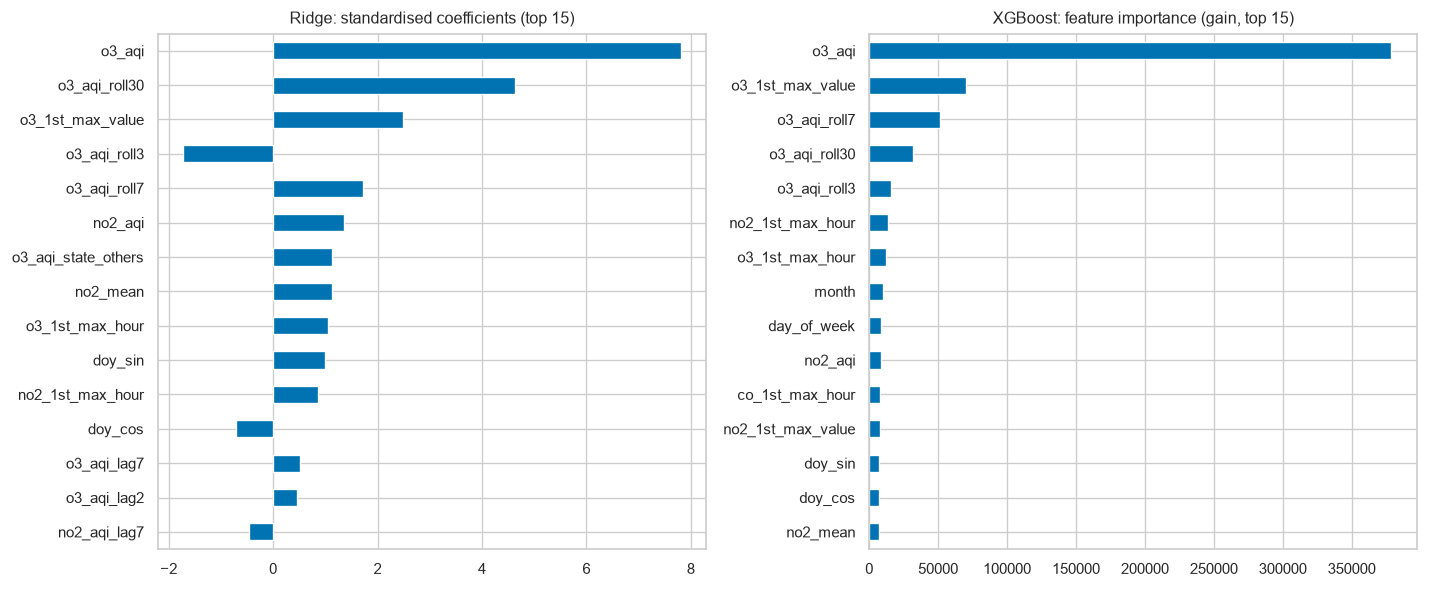

In [16]:
# What do the models rely on?
fig, axes = plt.subplots(1, 2 if HAS_XGB else 1, figsize=(12, 5), squeeze=False)

ridge_best = fitted["ridge"].best_estimator_
coefs = pd.Series(ridge_best[-1].coef_, index=ridge_best[:-1].get_feature_names_out(X_train.columns))
coefs.reindex(coefs.abs().sort_values().index).tail(15).plot.barh(ax=axes[0, 0])
axes[0, 0].set(title="Ridge: standardised coefficients (top 15)")

if HAS_XGB:
    gain = pd.Series(fitted["xgboost"].get_booster().get_score(importance_type="gain"))
    gain.sort_values().tail(15).plot.barh(ax=axes[0, 1])
    axes[0, 1].set(title="XGBoost: feature importance (gain, top 15)")
fig.tight_layout()

## 9. Weather features (later)

Placeholder for the meteostat experiment, once the pollution-only models above are done:

1. Get station coordinates (EPA AQS site list, joined on state / county / site codes).
2. Download daily weather per station with meteostat and cache it to `data/processed/`.
3. Merge on `station_id` + `date`, using only weather **up to day t** (no leakage).
4. Re-run sections 2–8 with and without weather and compare.

## 10. Final test evaluation (run once, at the very end)

Only after model choices and hyperparameters are frozen on the validation year.
Ideally refit on train + valid before scoring the test set.

In [ ]:
# X_test, y_test = features.split_xy(test)
# test_summary, test_per_station = evaluate_models(fitted, X_test, y_test, test[config.STATION_ID])
# if SAVE_ARTIFACTS:
#     test_summary.to_csv(config.TABLES_DIR / "metrics_test_summary.csv")
#     test_per_station.to_csv(config.TABLES_DIR / "metrics_test_stations.csv", index=False)
# test_summary.round(3)

## Moving this into `src/`

- [ ] `temporal_split`, `PersistenceBaseline`, `make_linear`, `get_models`, `train_all` → `models.py`
- [ ] `regression_metrics`, `station_metrics`, `summarise_stations`, `evaluate_models`,
  `paired_station_test` → `evaluation.py`
- [ ] `evaluate_models` now also needs the station ids: update `pipeline.run_evaluate` to pass
  `valid[config.STATION_ID]` (`split_xy` drops it) and to save both returned tables
- [ ] `climatology_forecast`, `fit_xgb`, `tune_xgb` → `models.py`
- [ ] `run_ablation`, `backtest` → `evaluation.py`
- [ ] `XGB_PARAMS` (the tuned values), `EARLY_STOP_FRAC`, `XGB_SEARCH_SPACE`, `N_TRIALS`, Ridge alpha grid, `MIN_DAYS`, `FEATURE_GROUPS`, `BACKTEST_YEARS` → `config.py`
- [ ] add `xgboost` to `pyproject.toml` (`just add xgboost`)
- [ ] check `just run train` and `just run evaluate` reproduce the table in section 8